# MARS-RL — Results notebook (executed)
**M**argin-constrained, **A**daptive, **R**egime-aware **S**afe RL on the Gu et al. (TKDE 2026) setting.

This notebook loads the saved, locked results and shows every table/figure of the paper. **All numbers are measured outputs, including negative ones.**
Set `RETRAIN=True` in the last section to regenerate everything from scratch (≈ 40 min on 2 CPU cores).

In [1]:
import sys, os, json, glob; from pathlib import Path
import pandas as pd, numpy as np
from IPython.display import display, Image, Markdown
ROOT = Path(os.getcwd()).parent if Path(os.getcwd()).name=='notebooks' else Path(os.getcwd())
sys.path.insert(0, str(ROOT)); pd.set_option('display.width', 250, 'display.max_columns', 30)
T = ROOT/'results/tables'; F = ROOT/'results/figures'
show = lambda name: display(Markdown((T/f'{name}.md').read_text()))

## 1. Data provenance and audit

In [2]:
print(open(ROOT/'data/manifests/raw_manifest.csv').read())
q = json.load(open(ROOT/'reports/data_quality.json'))
print({k:v for k,v in q.items() if k not in ('first_date_per_ticker','trackA_columns','tickers')})
raw = pd.read_csv(ROOT/'data/raw/ohlcv_yahoo_adjusted_28tickers.csv'); display(raw.head()); print(raw.shape)

file,sha256,rows,source,recorded_utc
data/raw/ohlcv_yahoo_adjusted_28tickers.csv,db27c84a82f89704c190c75f34636649a80ed5042626853e34a02639d16b3f08,101556,"yfinance auto_adjust=True, 28 DJIA tickers, downloaded by the user in Colab with margin_trader_dataset.ipynb",2026-11-06T10:41:59+00:00
data/raw/vix_daily_cboe_github_datasets.csv,570e05630c9a5e7350d0c3dbe3acc58e793cb5248181ab0e949c121cc082fb83,9278,CBOE VIX daily via github.com/datasets/finance-vix (fetched in sandbox),2026-11-06T10:41:59+00:00
third_party/margin_trader (authors code),commit 7b7fa9e89d8c202b80778b4f1fa82353841cfd52,0,github.com/JingyiGu/Margin-Trader (MIT),2026-11-06T10:41:59+00:00

{'rows': 101556, 'n_tickers': 28, 'date_min': '2009-01-02', 'date_max': '2023-05-31', 'duplicate_date_tic_keys': 0, 'nan_cells': 0, 'nonpositive_prices': 0, 'zero_volume_rows': 0, 'high_lt_max_open_close': 0, 'low_gt_min_open_close': 0, 'dates': 3627, 'dates_with_all_tickers': 3627, 'max_abs_daily_return': 0.2604488212597602, 'n_abs_retur

,date,tic,open,high,low,close,volume
0,2009-01-02,AAPL,2.568638,2.722972,2.547103,2.714297,746015200
1,2009-01-02,AMGN,39.104072,39.431108,38.543440,39.371040,6547900
2,2009-01-02,AXP,14.111145,14.833040,13.981963,14.688661,10955700
3,2009-01-02,BA,32.103406,34.173627,32.088404,33.941101,7010200
4,2009-01-02,CAT,28.618635,29.937731,28.491186,29.893124,7117200


(101556, 7)


## 2. Final processed model input (what the RL agents consume)

In [3]:
P = pd.read_csv(ROOT/'data/processed/model_input_features_panel.csv'); display(P[P.tic=='AAPL'].iloc[100:105].T)
display(P.groupby('split').date.agg(['min','max','nunique']))

,2800,2828,2856,2884,2912
date,2009-05-28,2009-05-29,2009-06-01,2009-06-02,2009-06-03
tic,AAPL,AAPL,AAPL,AAPL,AAPL
open,3.99144,4.04946,4.08177,4.15714,4.18735
close,4.03989,4.06203,4.16791,4.1721,4.21576
volume,487553000.0,456534000.0,452500000.0,456224000.0,565200000.0
ret1,0.301362,0.109263,0.514651,0.020082,0.208236
ret5,0.730916,0.936537,1.37551,0.666008,0.593756
ret20,0.396756,0.396564,0.475873,0.280912,0.310451
ret60,1.58538,1.4689,1.70565,1.90586,2.08784
vol20,0.772862,0.772858,0.785503,0.750873,0.752543


,min,max,nunique
split,,,
test,2020-05-01,2023-05-31,776
train,2009-03-31,2018-12-31,2456
val,2019-01-02,2020-04-30,335
warmup,2009-01-02,2009-03-30,60


## 3. Digital-twin fidelity (train-only regime-switching block bootstrap, 8 paths)

In [4]:
show('table_twin_fidelity')

|                  |   real_train |   twin (mean of 8 paths) |
|:-----------------|-------------:|-------------------------:|
| ann_vol          |       0.225  |                   0.2181 |
| excess_kurtosis  |       6.1652 |                   5.8948 |
| abs_ret_autocorr |       0.1605 |                   0.1419 |
| avg_corr         |       0.4079 |                   0.4085 |
| ew_maxdd         |      -0.1593 |                  -0.1925 |

## 4. Main results — test 2020-05 → 2023-05, common costs (Track B), mean ± sd over 3 seeds

In [5]:
show('table_main_test_cost1x')

|                                       | Ann. return    | Ann. vol      | Sharpe       | Sortino      | Max DD         | Calmar       | CVaR5 (daily)    | Avg gross   | Avg turnover   | Margin calls   | Costs (% init)   |
|:--------------------------------------|:---------------|:--------------|:-------------|:-------------|:---------------|:-------------|:-----------------|:------------|:---------------|:---------------|:-----------------|
| EW buy&hold (1x)                      | 0.137 ± 0.000  | 0.169 ± 0.000 | 0.85 ± 0.00  | 1.20 ± 0.00  | -0.216 ± 0.000 | 0.64 ± 0.00  | -0.0248 ± 0.0000 | 1.00 ± 0.00 | 0.000 ± 0.000  | 0.0 ± 0.0      | 0.000 ± 0.000    |
| EW daily-rebal (1x)                   | 0.138 ± 0.000  | 0.169 ± 0.000 | 0.85 ± 0.00  | 1.22 ± 0.00  | -0.211 ± 0.000 | 0.65 ± 0.00  | -0.0244 ± 0.0000 | 1.00 ± 0.00 | 0.010 ± 0.000  | 0.0 ± 0.0      | 0.013 ± 0.000    |
| EW daily-rebal (2x lev)               | 0.204 ± 0.000  | 0.338 ± 0.000 | 0.72 ± 0.00  | 1.03 ± 0.00  | -0.414 ± 0.000 | 0.49 ± 0.00  | -0.0488 ± 0.0000 | 2.00 ± 0.00 | 0.027 ± 0.000  | 0.0 ± 0.0      | 0.042 ± 0.000    |
| Min-variance (monthly)                | 0.120 ± 0.000  | 0.159 ± 0.000 | 0.79 ± 0.00  | 1.13 ± 0.00  | -0.212 ± 0.000 | 0.56 ± 0.00  | -0.0229 ± 0.0000 | 1.00 ± 0.00 | 0.005 ± 0.000  | 0.0 ± 0.0      | 0.005 ± 0.000    |
| Momentum top-7 (monthly)              | 0.097 ± 0.000  | 0.182 ± 0.000 | 0.60 ± 0.00  | 0.84 ± 0.00  | -0.236 ± 0.000 | 0.41 ± 0.00  | -0.0262 ± 0.0000 | 1.00 ± 0.00 | 0.043 ± 0.000  | 0.0 ± 0.0      | 0.054 ± 0.000    |
| PPO long-only 1x (plain reward)       | 0.041 ± 0.010  | 0.182 ± 0.008 | 0.32 ± 0.06  | 0.45 ± 0.09  | -0.269 ± 0.055 | 0.16 ± 0.06  | -0.0260 ± 0.0019 | 1.00 ± 0.00 | 0.423 ± 0.023  | 0.0 ± 0.0      | 0.471 ± 0.030    |
| PPO long-only 2x (paper-style reward) | -0.012 ± 0.045 | 0.364 ± 0.020 | 0.15 ± 0.12  | 0.21 ± 0.17  | -0.540 ± 0.078 | -0.02 ± 0.09 | -0.0523 ± 0.0037 | 2.00 ± 0.00 | 0.790 ± 0.010  | 0.0 ± 0.0      | 0.976 ± 0.062    |
| PPO 50/50 long-short 2x (paper-style) | -0.151 ± 0.080 | 0.108 ± 0.006 | -1.53 ± 0.92 | -1.98 ± 1.14 | -0.444 ± 0.118 | -0.32 ± 0.11 | -0.0153 ± 0.0003 | 2.00 ± 0.00 | 0.806 ± 0.057  | 0.0 ± 0.0      | 0.592 ± 0.080    |
| MARS expert: long                     | 0.025 ± 0.022  | 0.161 ± 0.002 | 0.23 ± 0.14  | 0.33 ± 0.20  | -0.273 ± 0.013 | 0.09 ± 0.08  | -0.0231 ± 0.0006 | 0.94 ± 0.01 | 0.384 ± 0.020  | 0.0 ± 0.0      | 0.408 ± 0.032    |
| MARS expert: long-short               | -0.093 ± 0.017 | 0.063 ± 0.003 | -1.51 ± 0.30 | -2.00 ± 0.39 | -0.291 ± 0.025 | -0.32 ± 0.04 | -0.0093 ± 0.0003 | 0.95 ± 0.01 | 0.379 ± 0.010  | 0.0 ± 0.0      | 0.300 ± 0.012    |
| MARS expert: neutral                  | -0.060 ± 0.023 | 0.037 ± 0.001 | -1.67 ± 0.69 | -2.15 ± 0.82 | -0.181 ± 0.065 | -0.33 ± 0.01 | -0.0055 ± 0.0001 | 0.71 ± 0.01 | 0.290 ± 0.019  | 0.0 ± 0.0      | 0.243 ± 0.014    |
| MARS-RL (retrieval gate)              | 0.004 ± 0.019  | 0.099 ± 0.006 | 0.10 ± 0.20  | 0.14 ± 0.28  | -0.184 ± 0.020 | 0.03 ± 0.11  | -0.0143 ± 0.0008 | 0.78 ± 0.01 | 0.323 ± 0.012  | 0.0 ± 0.0      | 0.321 ± 0.017    |
| MARS uniform mix                      | -0.017 ± 0.014 | 0.067 ± 0.003 | -0.21 ± 0.21 | -0.29 ± 0.28 | -0.156 ± 0.029 | -0.10 ± 0.08 | -0.0097 ± 0.0007 | 0.72 ± 0.01 | 0.293 ± 0.010  | 0.0 ± 0.0      | 0.274 ± 0.007    |
| MARS gate, shuffled memory            | 0.001 ± 0.016  | 0.094 ± 0.008 | 0.06 ± 0.17  | 0.09 ± 0.24  | -0.187 ± 0.020 | 0.01 ± 0.08  | -0.0136 ± 0.0011 | 0.77 ± 0.01 | 0.320 ± 0.014  | 0.0 ± 0.0      | 0.314 ± 0.017    |

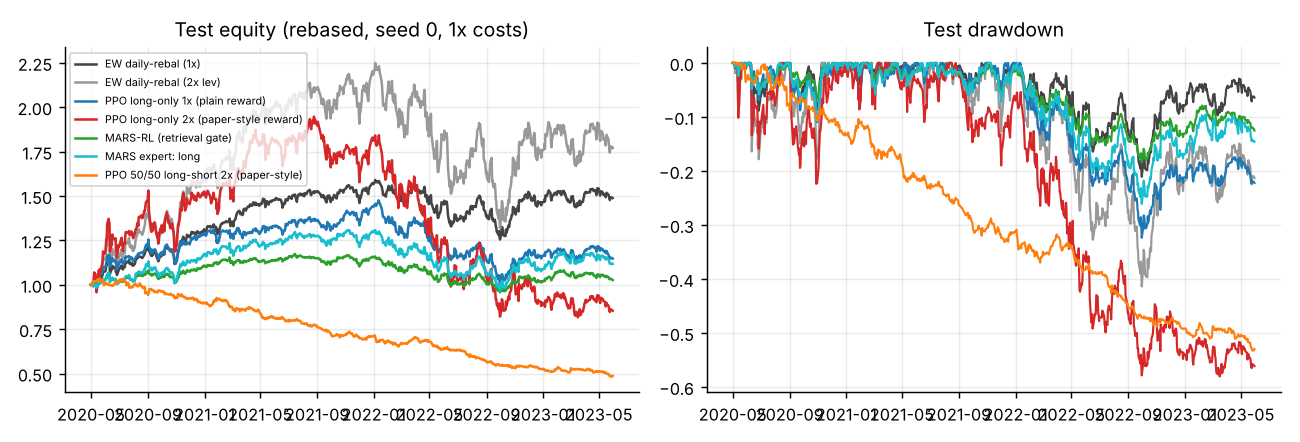

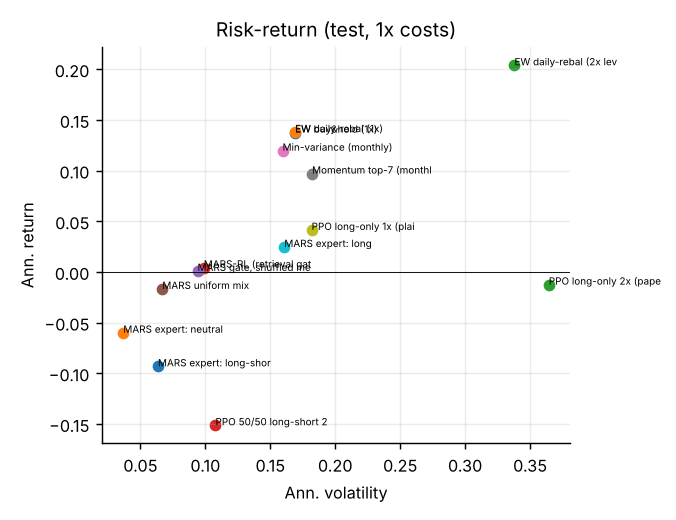

In [6]:
display(Image(str(F/'fig2_equity_drawdown.png'))); display(Image(str(F/'fig3_risk_return.png')))

### Validation period (2019-01 → 2020-04), used for checkpoint selection only

In [7]:
show('table_main_val_cost1x')

|                                       | Ann. return    | Ann. vol      | Sharpe       | Sortino      | Max DD         | Calmar       | CVaR5 (daily)    | Avg gross   | Avg turnover   | Margin calls   | Costs (% init)   |
|:--------------------------------------|:---------------|:--------------|:-------------|:-------------|:---------------|:-------------|:-----------------|:------------|:---------------|:---------------|:-----------------|
| EW buy&hold (1x)                      | 0.118 ± 0.000  | 0.289 ± 0.000 | 0.53 ± 0.00  | 0.75 ± 0.00  | -0.330 ± 0.000 | 0.36 ± 0.00  | -0.0466 ± 0.0000 | 1.00 ± 0.00 | 0.003 ± 0.000  | 0.0 ± 0.0      | 0.001 ± 0.000    |
| EW daily-rebal (1x)                   | 0.120 ± 0.000  | 0.293 ± 0.000 | 0.53 ± 0.00  | 0.75 ± 0.00  | -0.336 ± 0.000 | 0.36 ± 0.00  | -0.0471 ± 0.0000 | 1.00 ± 0.00 | 0.012 ± 0.000  | 0.0 ± 0.0      | 0.005 ± 0.000    |
| EW daily-rebal (2x lev)               | 0.138 ± 0.000  | 0.587 ± 0.000 | 0.52 ± 0.00  | 0.74 ± 0.00  | -0.578 ± 0.000 | 0.24 ± 0.00  | -0.0930 ± 0.0000 | 1.99 ± 0.00 | 0.032 ± 0.000  | 0.0 ± 0.0      | 0.015 ± 0.000    |
| Min-variance (monthly)                | 0.067 ± 0.000  | 0.281 ± 0.000 | 0.37 ± 0.00  | 0.51 ± 0.00  | -0.333 ± 0.000 | 0.20 ± 0.00  | -0.0462 ± 0.0000 | 1.00 ± 0.00 | 0.009 ± 0.000  | 0.0 ± 0.0      | 0.004 ± 0.000    |
| Momentum top-7 (monthly)              | 0.057 ± 0.000  | 0.293 ± 0.000 | 0.34 ± 0.00  | 0.46 ± 0.00  | -0.341 ± 0.000 | 0.17 ± 0.00  | -0.0481 ± 0.0000 | 1.00 ± 0.00 | 0.041 ± 0.000  | 0.0 ± 0.0      | 0.019 ± 0.000    |
| PPO long-only 1x (plain reward)       | 0.080 ± 0.055  | 0.307 ± 0.013 | 0.40 ± 0.16  | 0.57 ± 0.24  | -0.334 ± 0.018 | 0.24 ± 0.17  | -0.0492 ± 0.0011 | 1.00 ± 0.00 | 0.422 ± 0.022  | 0.0 ± 0.0      | 0.191 ± 0.009    |
| PPO long-only 2x (paper-style reward) | -0.013 ± 0.090 | 0.604 ± 0.024 | 0.28 ± 0.14  | 0.41 ± 0.21  | -0.570 ± 0.056 | -0.01 ± 0.16 | -0.0954 ± 0.0083 | 2.00 ± 0.00 | 0.841 ± 0.007  | 0.0 ± 0.0      | 0.387 ± 0.006    |
| PPO 50/50 long-short 2x (paper-style) | -0.128 ± 0.049 | 0.120 ± 0.005 | -1.10 ± 0.52 | -1.52 ± 0.58 | -0.248 ± 0.043 | -0.51 ± 0.14 | -0.0171 ± 0.0016 | 2.00 ± 0.00 | 0.803 ± 0.028  | 0.0 ± 0.0      | 0.293 ± 0.011    |
| MARS expert: long                     | 0.045 ± 0.005  | 0.158 ± 0.001 | 0.36 ± 0.03  | 0.47 ± 0.04  | -0.214 ± 0.010 | 0.21 ± 0.03  | -0.0276 ± 0.0001 | 0.89 ± 0.02 | 0.348 ± 0.020  | 0.0 ± 0.0      | 0.159 ± 0.007    |
| MARS expert: long-short               | -0.089 ± 0.062 | 0.082 ± 0.018 | -1.03 ± 0.59 | -1.39 ± 0.76 | -0.167 ± 0.066 | -0.49 ± 0.19 | -0.0121 ± 0.0035 | 0.95 ± 0.01 | 0.387 ± 0.013  | 0.0 ± 0.0      | 0.146 ± 0.008    |
| MARS expert: neutral                  | -0.066 ± 0.032 | 0.038 ± 0.005 | -1.88 ± 1.20 | -2.43 ± 1.33 | -0.108 ± 0.027 | -0.59 ± 0.13 | -0.0055 ± 0.0006 | 0.72 ± 0.02 | 0.318 ± 0.033  | 0.0 ± 0.0      | 0.120 ± 0.010    |
| MARS-RL (retrieval gate)              | -0.040 ± 0.006 | 0.119 ± 0.004 | -0.28 ± 0.04 | -0.36 ± 0.05 | -0.169 ± 0.014 | -0.23 ± 0.04 | -0.0214 ± 0.0007 | 0.73 ± 0.00 | 0.302 ± 0.017  | 0.0 ± 0.0      | 0.124 ± 0.006    |
| MARS uniform mix                      | -0.036 ± 0.027 | 0.095 ± 0.009 | -0.32 ± 0.27 | -0.42 ± 0.35 | -0.137 ± 0.018 | -0.25 ± 0.18 | -0.0158 ± 0.0018 | 0.70 ± 0.02 | 0.291 ± 0.015  | 0.0 ± 0.0      | 0.118 ± 0.006    |
| MARS gate, shuffled memory            | -0.034 ± 0.013 | 0.111 ± 0.004 | -0.25 ± 0.11 | -0.32 ± 0.15 | -0.163 ± 0.005 | -0.21 ± 0.09 | -0.0195 ± 0.0007 | 0.72 ± 0.02 | 0.301 ± 0.011  | 0.0 ± 0.0      | 0.123 ± 0.004    |

## 5. Cost stress (1×, 2×, 3× all frictions) — models trained at 1×

| model                                 |   ('sharpe', '1x') |   ('sharpe', '2x') |   ('sharpe', '3x') |   ('ann_return', '1x') |   ('ann_return', '2x') |   ('ann_return', '3x') |
|:--------------------------------------|-------------------:|-------------------:|-------------------:|-----------------------:|-----------------------:|-----------------------:|
| EW buy&hold (1x)                      |              0.847 |              0.846 |              0.845 |                  0.137 |                  0.137 |                  0.137 |
| EW daily-rebal (1x)                   |              0.849 |              0.831 |              0.813 |                  0.138 |                  0.135 |                  0.131 |
| EW daily-rebal (2x lev)               |              0.719 |              0.577 |              0.435 |                  0.204 |                  0.147 |                  0.094 |
| MARS expert: long                     |              0.231 |             -0.48  |             -1.166 |                  0.025 |                 -0.086 |                 -0.182 |
| MARS expert: long-short               |             -1.511 |             -3.382 |             -5.206 |                 -0.093 |                 -0.194 |                 -0.282 |
| MARS expert: neutral                  |             -1.672 |             -4.018 |             -6.281 |                 -0.06  |                 -0.139 |                 -0.21  |
| MARS gate, shuffled memory            |              0.058 |             -0.802 |             -1.605 |                  0.001 |                 -0.086 |                 -0.168 |
| MARS uniform mix                      |             -0.214 |             -1.542 |             -2.844 |                 -0.017 |                 -0.1   |                 -0.175 |
| MARS-RL (retrieval gate)              |              0.095 |             -0.782 |             -1.59  |                  0.004 |                 -0.086 |                 -0.168 |
| Min-variance (monthly)                |              0.789 |              0.78  |              0.77  |                  0.12  |                  0.118 |                  0.116 |
| Momentum top-7 (monthly)              |              0.6   |              0.528 |              0.455 |                  0.097 |                  0.083 |                  0.069 |
| PPO 50/50 long-short 2x (paper-style) |             -1.528 |             -3.69  |             -5.806 |                 -0.151 |                 -0.33  |                 -0.486 |
| PPO long-only 1x (plain reward)       |              0.316 |             -0.384 |             -1.044 |                  0.041 |                 -0.084 |                 -0.189 |
| PPO long-only 2x (paper-style reward) |              0.15  |             -0.588 |             -1.029 |                 -0.012 |                 -0.247 |                 -0.335 |

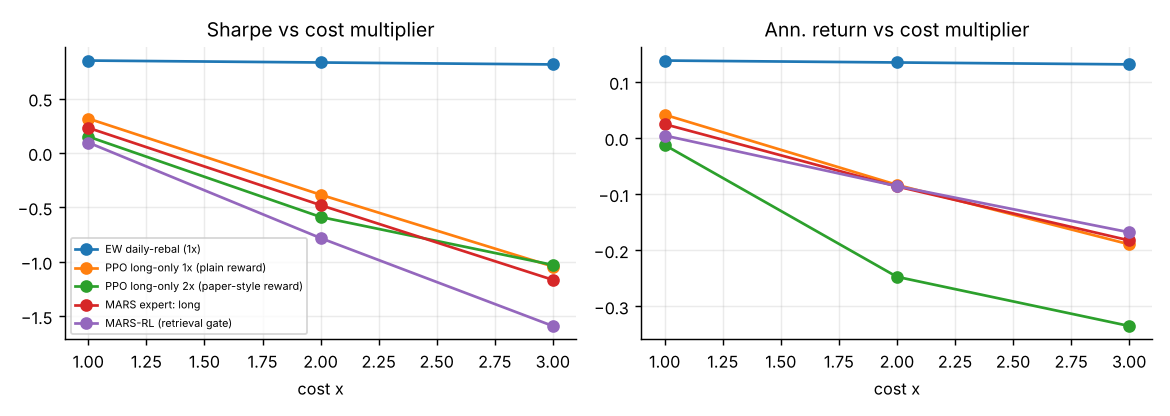

In [8]:
show('table_cost_stress'); display(Image(str(F/'fig4_cost_stress.png')))

## 6. Ablations

|                                   | Sharpe       | Ann. return    | Max DD         | Avg gross   |
|:----------------------------------|:-------------|:---------------|:---------------|:------------|
| Ablation: L/S, no CMDP/guard/twin | -0.31 ± 0.64 | -0.001 ± 0.001 | -0.005 ± 0.001 | 0.00 ± 0.00 |
| Ablation: MARS L/S, no twin       | -1.90 ± 0.17 | -0.119 ± 0.021 | -0.329 ± 0.046 | 0.97 ± 0.01 |
| MARS expert: long-short           | -1.51 ± 0.30 | -0.093 ± 0.017 | -0.291 ± 0.025 | 0.95 ± 0.01 |
| fixed-mars_ls                     | -1.51 ± 0.30 | -0.093 ± 0.017 | -0.291 ± 0.025 | 0.95 ± 0.01 |
| MARS expert: long                 | 0.23 ± 0.14  | 0.025 ± 0.022  | -0.273 ± 0.013 | 0.94 ± 0.01 |
| MARS expert: neutral              | -1.67 ± 0.69 | -0.060 ± 0.023 | -0.181 ± 0.065 | 0.71 ± 0.01 |
| MARS uniform mix                  | -0.21 ± 0.21 | -0.017 ± 0.014 | -0.156 ± 0.029 | 0.72 ± 0.01 |
| MARS gate, shuffled memory        | 0.06 ± 0.17  | 0.001 ± 0.016  | -0.187 ± 0.020 | 0.77 ± 0.01 |
| MARS-RL (retrieval gate)          | 0.10 ± 0.20  | 0.004 ± 0.019  | -0.184 ± 0.020 | 0.78 ± 0.01 |

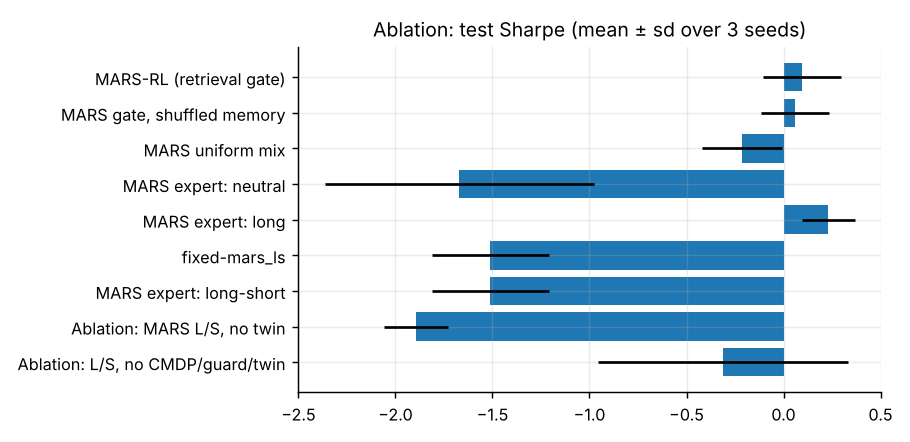

In [9]:
show('table_ablation'); display(Image(str(F/'fig5_ablation.png')))

## 7. Statistical tests (test period; paired stationary bootstrap, Jobson–Korkie–Memmel, deflated Sharpe)

In [10]:
show('table_significance')

|                                                            |   sharpe_diff |   ci_low |   ci_high |   p_boot_one_sided |    p_JKM |
|:-----------------------------------------------------------|--------------:|---------:|----------:|-------------------:|---------:|
| (0, 'EW daily-rebal (1x)')                                 |       -0.7155 |  -1.1624 |   -0.2758 |             0.999  |   0.001  |
| (0, 'PPO long-only 1x (plain reward)')                     |       -0.2047 |  -0.7333 |    0.3248 |             0.7795 |   0.4571 |
| (0, 'PPO long-only 2x (paper-style reward)')               |        0.0859 |  -0.4815 |    0.6657 |             0.38   |   0.7536 |
| (0, 'DSR (P[true SR>0] after selection among val trials)') |        0.1337 | nan      |  nan      |             0.9997 | nan      |
| (1, 'EW daily-rebal (1x)')                                 |       -0.5767 |  -1.073  |   -0.0616 |             0.989  |   0.049  |
| (1, 'PPO long-only 1x (plain reward)')                     |        0.0227 |  -0.5946 |    0.6631 |             0.444  |   0.9481 |
| (1, 'PPO long-only 2x (paper-style reward)')               |        0.1491 |  -0.3743 |    0.7014 |             0.282  |   0.646  |
| (1, 'DSR (P[true SR>0] after selection among val trials)') |        0.2724 | nan      |  nan      |             0.9992 | nan      |
| (2, 'EW daily-rebal (1x)')                                 |       -0.9689 |  -1.4879 |   -0.4846 |             1      |   0.0001 |
| (2, 'PPO long-only 1x (plain reward)')                     |       -0.4794 |  -1.0382 |    0.1071 |             0.942  |   0.1255 |
| (2, 'PPO long-only 2x (paper-style reward)')               |       -0.3993 |  -1.0065 |    0.2389 |             0.889  |   0.2056 |
| (2, 'DSR (P[true SR>0] after selection among val trials)') |       -0.1197 | nan      |  nan      |             0.9999 | nan      |

## 8. Digital-twin crash stress (250-day synthetic crash paths, drift −0.15%/day, vol ×1.3)

|                                       |   Acc. return |   Max DD |   Worst-path MDD |   CVaR5 daily |
|:--------------------------------------|--------------:|---------:|-----------------:|--------------:|
| EW buy&hold (1x)                      |        -0.202 |   -0.27  |           -0.317 |        -0.028 |
| EW daily-rebal (1x)                   |        -0.189 |   -0.261 |           -0.312 |        -0.028 |
| EW daily-rebal (2x lev)               |        -0.376 |   -0.478 |           -0.549 |        -0.055 |
| Min-variance (monthly)                |        -0.183 |   -0.257 |           -0.31  |        -0.027 |
| Momentum top-7 (monthly)              |        -0.268 |   -0.331 |           -0.399 |        -0.032 |
| PPO long-only 1x (plain reward)       |        -0.254 |   -0.311 |           -0.389 |        -0.029 |
| PPO long-only 2x (paper-style reward) |        -0.463 |   -0.542 |           -0.629 |        -0.059 |
| PPO 50/50 long-short 2x (paper-style) |        -0.134 |   -0.177 |           -0.274 |        -0.017 |
| MARS expert: long                     |        -0.249 |   -0.304 |           -0.398 |        -0.027 |
| MARS expert: long-short               |        -0.113 |   -0.132 |           -0.193 |        -0.011 |
| MARS expert: neutral                  |        -0.072 |   -0.081 |           -0.142 |        -0.006 |
| MARS-RL (retrieval gate)              |        -0.135 |   -0.163 |           -0.234 |        -0.014 |
| MARS uniform mix                      |        -0.134 |   -0.161 |           -0.215 |        -0.013 |
| MARS gate, shuffled memory            |        -0.132 |   -0.16  |           -0.228 |        -0.013 |

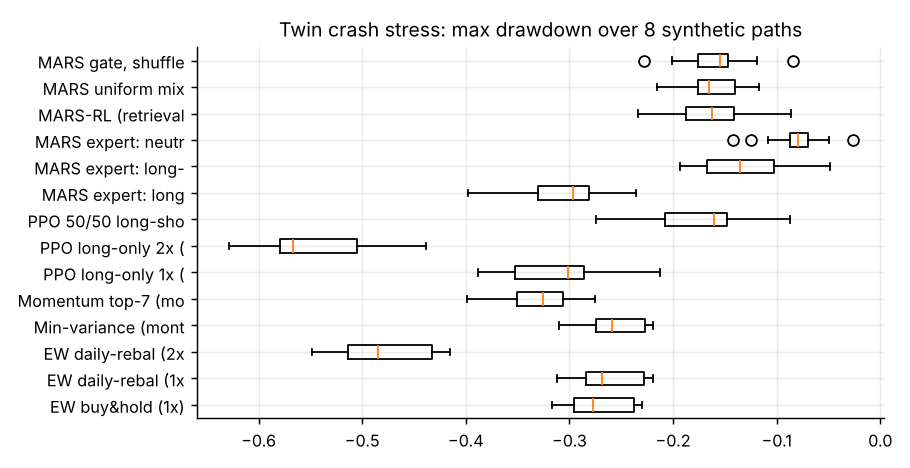

In [11]:
show('table_twin_crash'); display(Image(str(F/'fig7_twin_crash.png')))

## 9. Training diagnostics (validation Sharpe, CMDP dual multipliers) and exposure

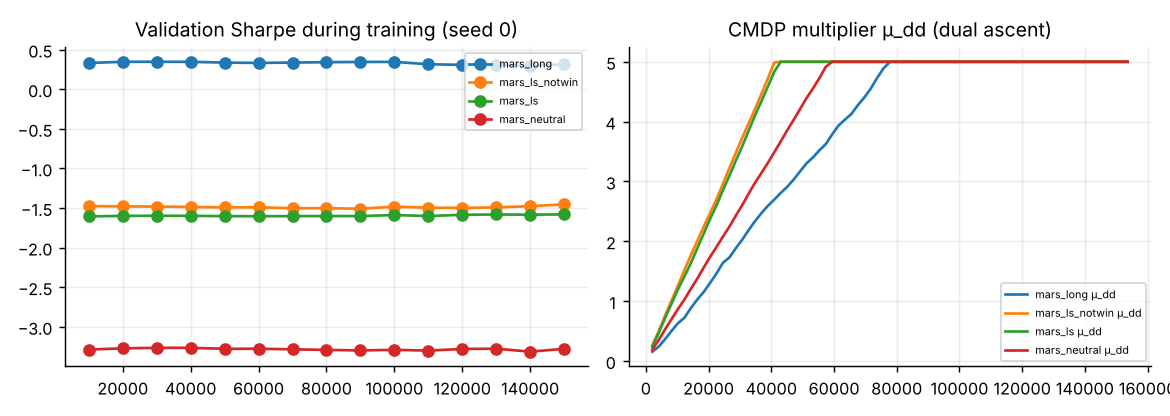

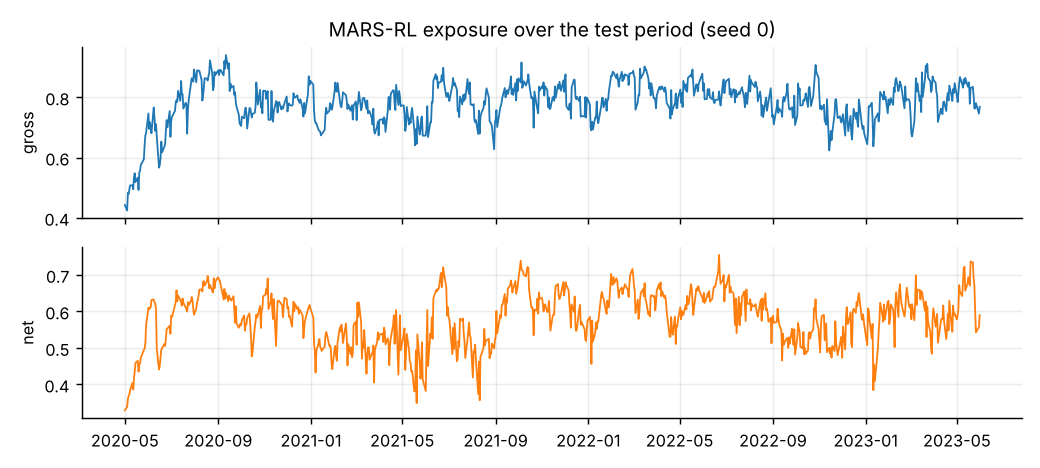

In [12]:
display(Image(str(F/'fig6_training_dual.png'))); display(Image(str(F/'fig9_exposure.png')))

## 10. Track A — the authors' own simulator and A2C/PPO code, on our data (NOT comparable to Track B numbers)

| run    |   test_acc_return |   test_ann_return |   test_ann_vol |   test_sharpe |   test_sortino |   test_max_drawdown |   test_calmar |   test_cvar5_daily |
|:-------|------------------:|------------------:|---------------:|--------------:|---------------:|--------------------:|--------------:|-------------------:|
| a2c_s0 |             0.589 |             0.168 |          0.313 |         0.652 |          0.944 |              -0.273 |         0.615 |             -0.044 |
| a2c_s1 |             0.361 |             0.109 |          0.278 |         0.51  |          0.737 |              -0.297 |         0.367 |             -0.038 |
| a2c_s2 |             0.177 |             0.056 |          0.276 |         0.335 |          0.487 |              -0.401 |         0.14  |             -0.037 |
| ppo_s0 |             0.249 |             0.077 |          0.21  |         0.46  |          0.645 |              -0.229 |         0.337 |             -0.031 |
| ppo_s1 |             0.499 |             0.145 |          0.226 |         0.712 |          1.037 |              -0.231 |         0.627 |             -0.031 |
| ppo_s2 |             0.368 |             0.111 |          0.2   |         0.623 |          0.895 |              -0.202 |         0.547 |             -0.027 |

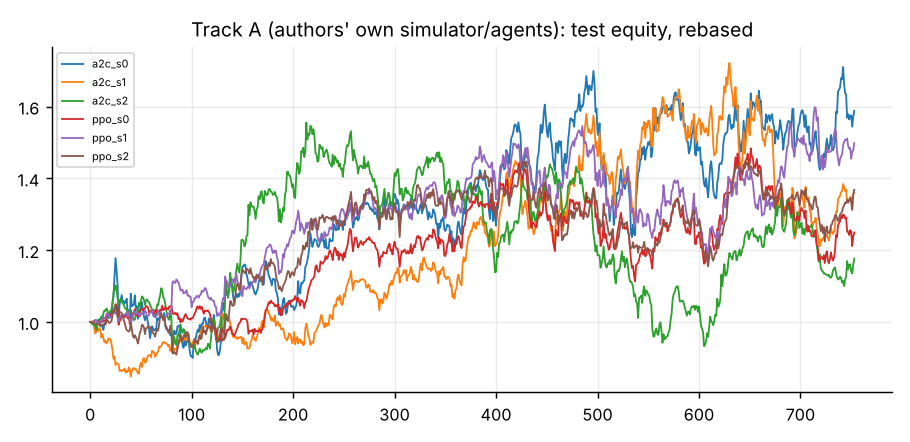

In [13]:
show('table_trackA_runs'); display(Image(str(F/'fig8_trackA.png')))

## 11. Conclusions (from the measured numbers above)
* MARS-RL did **not** beat the equal-weight baseline or the authors' agents on risk-adjusted return in this replication; the Sharpe gap vs equal-weight is statistically significant against MARS-RL.
* It **did** lower drawdown/CVaR relative to leveraged long-only agents and in the synthetic crash stress; it has zero margin calls.
* The gate beats uniform mixing but is statistically indistinguishable from shuffled memory → no evidence that retrieval itself adds value.
* RL agents are highly cost-sensitive (turnover 0.3–0.8/day); at 2×–3× costs they turn clearly negative.
* The LLM/agentic layer is code-only and was not evaluated here (no news data / model weights in the sandbox).

## 12. Optional: regenerate everything

In [14]:
RETRAIN = False
if RETRAIN:
    import subprocess
    for c in ['python -m src.data_prep','python -m src.export_processed','bash scripts/run_stage.sh 150000 models/stage2 "0 1 2" "finrl_long mt_long mt_split mars_long mars_ls mars_neutral plain_ls mars_ls_notwin"',
              'python -m src.evaluate','python -m src.stress_twin','bash scripts/run_track_a.sh','python -m src.report']:
        print('>>', c); subprocess.run(c, shell=True, cwd=ROOT, check=True)
else:
    print('Retraining skipped (RETRAIN=False).')
print('Unit tests:'); import subprocess; print(subprocess.run('python -m pytest tests -q', shell=True, cwd=ROOT, capture_output=True, text=True).stdout[-300:])

Retraining skipped (RETRAIN=False).
Unit tests:


........                                                                 [100%]
8 passed in 1.35s

